# Data: machine M01
Machine M01, only the operations that have both good and bad recordings. Day 1 looks at OP01 in detail, and Day 2 looks at all of them. All numbers below come from the code cells.

## Day 1 – what makes the bad recordings anomalies
The dataset README only says that "bad" means anomalous vibration data (line 28). It doesn't say what went wrong in each file. So today I look at what the 2 bad OP01 recordings do differently from the good ones: which axis, which frequency, and how strongly.

### Setup
Facts used here, all from primary sources:
- sampling rate 2000 Hz (dataset README line 15)
- columns 0, 1, 2 are X, Y, Z (README line 37)
- OP01 spindle speed 250 Hz and typical length 29 s (paper, Table 1)

The values have no unit in any source, so they stay raw "counts".

In [1]:
from pathlib import Path
import h5py, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch

FS = 2000          # Hz, README line 15
AXES = 'XYZ'       # column order, README line 37
SPINDLE = 250      # Hz, OP01 spindle speed, paper Table 1
DIR = Path('../data/CNC_Machining/data/M01/OP01')
GOOD, BAD = '#2a78d6', '#eb6834'

def load(path):
    """(n, 3) array in counts, columns X, Y, Z."""
    with h5py.File(path) as f:
        return f['vibration_data'][()].astype(float)

### Inventory
One row per file. The filename gives machine, month, year, operation and file number. The folder (`good`/`bad`) gives the label. The month and year mark the end of a 6-month collection period (README line 15).

In [2]:
rows = []
for p in sorted(DIR.glob('*/*.h5')):
    _, month, year, _, num = p.stem.split('_')
    rows.append(dict(period=pd.to_datetime(month + year, format='%b%Y').strftime('%Y-%m'),
                     label=p.parent.name, num=num, path=p))
idx = pd.DataFrame(rows).sort_values(['period', 'label', 'num'], ignore_index=True)
print(idx.groupby(['period', 'label']).size().unstack(fill_value=0))

label    bad  good
period            
2019-02    1     5
2019-08    1    14
2020-02    0     4
2021-02    0    15


### Compare inside the same period
The machine can change between periods (tool wear, maintenance), so each bad recording is only compared with the good recordings from its own period: 2019-02 and 2019-08. I remove each recording's mean before computing RMS, because a constant offset is not vibration. Z sits near -1000 counts, which is probably gravity, but no source says so.

In [3]:
same = idx[idx['period'].isin(['2019-02', '2019-08'])].copy()
sig = {i: load(p) for i, p in same['path'].items()}
same['length_s'] = [len(sig[i]) / FS for i in same.index]
for a, ax in enumerate(AXES):
    same[f'rms_{ax}'] = [np.sqrt(((sig[i][:, a] - sig[i][:, a].mean()) ** 2).mean()) for i in same.index]
print(same.drop(columns='path').round(1).to_string(index=False))

 period label num  length_s  rms_X  rms_Y  rms_Z
2019-02   bad 000      23.5  457.5  176.3  223.6
2019-02  good 000      29.4  424.0  140.4  165.1
2019-02  good 001      29.4  423.8  140.8  161.8
2019-02  good 002      29.4  423.3  142.8  163.2
2019-02  good 003      28.2  422.8  140.8  167.7
2019-02  good 004      30.0  418.7  139.2  162.8
2019-08   bad 000      19.5  447.9  228.1  242.0
2019-08  good 000      30.2  424.6  169.5  168.8
2019-08  good 001      29.7  427.3  171.1  168.2
2019-08  good 002      27.6  434.7  164.6  175.0
2019-08  good 003      29.7  428.2  164.7  159.5
2019-08  good 004      30.2  424.6  159.9  158.7
2019-08  good 005      30.2  424.1  159.4  159.4
2019-08  good 006      29.7  427.5  174.0  171.0
2019-08  good 007      32.3  414.3  161.3  193.3
2019-08  good 008      29.7  428.5  161.0  164.1
2019-08  good 009      29.7  428.7  160.5  162.9
2019-08  good 010      30.2  424.7  156.5  161.4
2019-08  good 011      30.2  423.2  159.4  163.3
2019-08  good 012   

### Time signals
One good and the bad recording from 2019-08, each axis on its own row. The mean is removed so the axes can share one scale.

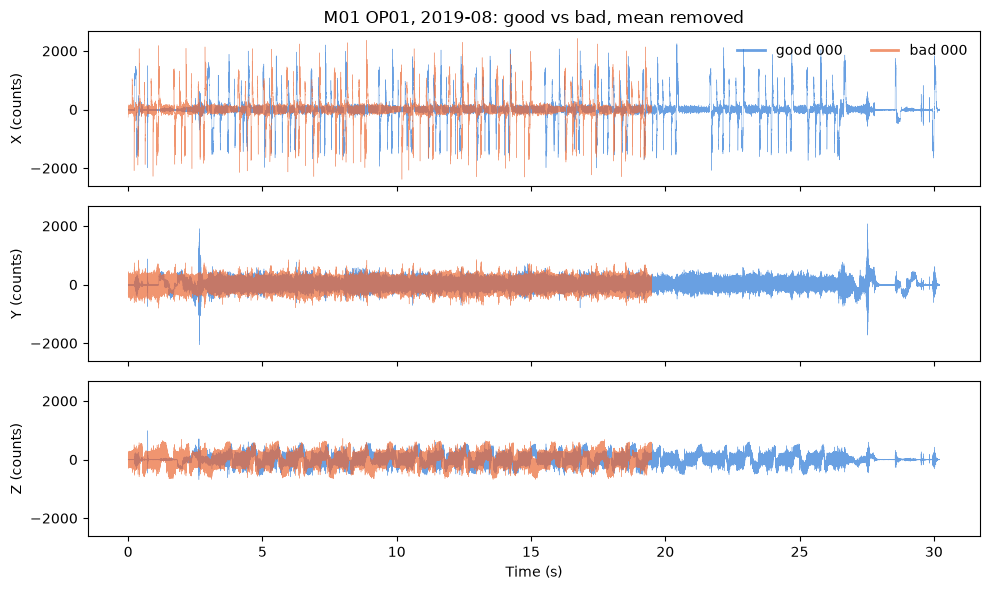

In [4]:
good_i = same[(same['period'] == '2019-08') & (same['label'] == 'good')].index[0]
bad_i = same[(same['period'] == '2019-08') & (same['label'] == 'bad')].index[0]
fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True, sharey=True)
for a, ax in enumerate(axs):
    for i, color, name in [(good_i, GOOD, 'good 000'), (bad_i, BAD, 'bad 000')]:
        x = sig[i][:, a] - sig[i][:, a].mean()
        ax.plot(np.arange(len(x)) / FS, x, color=color, lw=.3, alpha=.7, label=name)
    ax.set_ylabel(f'{AXES[a]} (counts)')
for line in axs[0].legend(frameon=False, loc='upper right', ncol=2).get_lines():
    line.set_linewidth(2)  # the plotted lines are thin, the legend shouldn't be
axs[0].set_title('M01 OP01, 2019-08: good vs bad, mean removed')
axs[-1].set_xlabel('Time (s)')
fig.tight_layout()
plt.show()

### Spectra (Welch PSD)
A spectrum shows how much of the vibration sits at each frequency. Welch's method cuts the signal into overlapping pieces of 1024 samples, computes a spectrum for each and averages them, which gives a smooth curve. For the good recordings I take the median over all good files of the period, so one unusual file can't move the curve much. The dotted line marks the 250 Hz spindle speed.

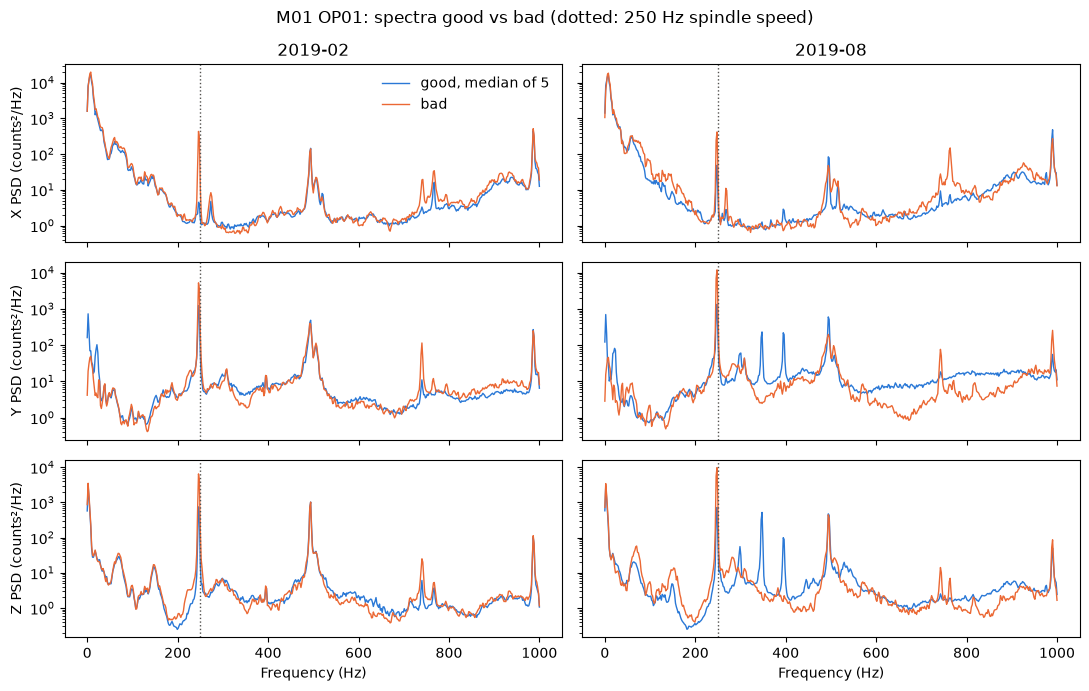

In [5]:
def psd(x):
    f, p = welch(x - x.mean(axis=0), FS, nperseg=1024, axis=0)
    return f, p

f = psd(sig[good_i])[0]
fig, axs = plt.subplots(3, 2, figsize=(11, 7), sharex=True, sharey='row')
for c, period in enumerate(['2019-02', '2019-08']):
    g = same[(same['period'] == period) & (same['label'] == 'good')].index
    b = same[(same['period'] == period) & (same['label'] == 'bad')].index[0]
    good_med = np.median([psd(sig[i])[1] for i in g], axis=0)
    bad_p = psd(sig[b])[1]
    for a in range(3):
        ax = axs[a, c]
        ax.semilogy(f, good_med[:, a], color=GOOD, lw=1, label=f'good, median of {len(g)}')
        ax.semilogy(f, bad_p[:, a], color=BAD, lw=1, label='bad')
        ax.axvline(SPINDLE, color='#52514e', ls=':', lw=1)
        if c == 0:
            ax.set_ylabel(f'{AXES[a]} PSD (counts²/Hz)')
    axs[0, c].set_title(f'{period}')
axs[0, 0].legend(frameon=False)
for ax in axs[-1]:
    ax.set_xlabel('Frequency (Hz)')
fig.suptitle('M01 OP01: spectra good vs bad (dotted: 250 Hz spindle speed)')
fig.tight_layout()
fig.savefig('../results/figures/m01_op01_spectra.png', dpi=150)
plt.show()

### How big is the difference?
Energy per frequency band, bad divided by the good median, in decibels: dB = 10 · log10(bad / good). 0 dB means equal, +3 dB is about twice the energy and +10 dB ten times. The 200–400 Hz band holds the spindle speed. I also print where each spectrum has its highest peak.

In [6]:
BANDS = [(0, 50), (50, 100), (100, 200), (200, 400), (400, 700), (700, 1000)]
for period in ['2019-02', '2019-08']:
    g = same[(same['period'] == period) & (same['label'] == 'good')].index
    b = same[(same['period'] == period) & (same['label'] == 'bad')].index[0]
    good_med = np.median([psd(sig[i])[1] for i in g], axis=0)
    bad_p = psd(sig[b])[1]
    table = {f'{lo}-{hi} Hz': 10 * np.log10(bad_p[(f >= lo) & (f < hi)].sum(axis=0) / good_med[(f >= lo) & (f < hi)].sum(axis=0))
             for lo, hi in BANDS}
    print(period, 'bad vs good median (dB)')
    print(pd.DataFrame(table, index=list(AXES)).round(1).to_string())
    print('highest peak (Hz)  good:', f[good_med.argmax(axis=0)], ' bad:', f[bad_p.argmax(axis=0)], '\n')

2019-02 bad vs good median (dB)
   0-50 Hz  50-100 Hz  100-200 Hz  200-400 Hz  400-700 Hz  700-1000 Hz
X      0.6        1.0         0.7         8.1         0.1          1.2
Y     -7.6        0.3        -0.1         5.1         0.0          1.6
Z      0.8        0.7         0.7         8.7        -0.2          1.2
highest peak (Hz)  good: [  7.8125   246.09375    1.953125]  bad: [  7.8125  246.09375 246.09375] 

2019-08 bad vs good median (dB)
   0-50 Hz  50-100 Hz  100-200 Hz  200-400 Hz  400-700 Hz  700-1000 Hz
X      0.2        1.9         3.1         6.0         0.2          0.9
Y     -7.5        2.8        -0.3         6.6        -1.4         -0.8
Z      0.8        3.2         4.3         7.8        -0.7         -0.4
highest peak (Hz)  good: [  7.8125   248.046875   1.953125]  bad: [  7.8125   248.046875 248.046875] 



### What Day 1 shows
- **Shorter files.** The bad recordings last 23.5 s and 19.5 s, against 27.6 to 32.3 s for the good ones. The authors cut the start and end off bad files during labelling (paper p. 135), so the length gives the label away. A model must not be allowed to use it.
- **More vibration on every axis.** In both periods the bad recording has a higher RMS than every good recording, on all three axes. The gap is small on X (448–458 vs 414–435 counts) and large on Y (176–228 vs 139–174) and Z (224–242 vs 159–193).
- **The extra energy sits at the spindle speed.** The 200–400 Hz band, which holds the 250 Hz spindle speed, is 5.1 to 8.7 dB higher in both bad recordings, on all axes. On Z the strongest peak moves from about 2 Hz in the good median to 246–248 Hz in the bad recordings. Most other bands differ by less than 3 dB.
- **One drop:** Y below 50 Hz is about 7.5 dB lower in both bad recordings. In the time plot the good file has large Y spikes at its start and end. The bad files lost their start and end, which may explain this. That is a hypothesis, not yet tested.

**Why they are anomalies:** every turn of the spindle shakes the machine harder than in a normal OP01 run. The paper names tool misalignment, chips clamped in the tool, chips in the chuck and tool breakage as causes of bad runs (p. 134), but the data doesn't say which one happened here. Extra vibration at exactly the rotation speed fits an off-centre or unbalanced tool. This is my interpretation, not a fact from the data.

With only 2 bad recordings, these are two examples, not a general rule.

## Day 2 – M01: what the anomaly looks like in each operation
Day 1 found that the two bad OP01 runs vibrate harder at the spindle speed. Today I check whether that holds for every M01 operation, or whether other operations fail in other ways. The answer decides which features the model needs.

### Which operations
I keep only the operations that have at least one bad recording. OP00 and OP13 have none, so they can't show whether a model detects anything. I chose this before training anything.

In [7]:
rows = []
for p in sorted(DIR.parent.glob('OP*/*/*.h5')):
    _, month, year, op, num = p.stem.split('_')
    rows.append(dict(op=op, period=pd.to_datetime(month + year, format='%b%Y').strftime('%Y-%m'),
                     label=p.parent.name, num=num, path=p))
m01 = pd.DataFrame(rows)
has_bad = m01.groupby('op')['label'].apply(lambda s: (s == 'bad').any())
print('left out (no bad recordings):', list(has_bad[~has_bad].index))
m01 = m01[m01['op'].isin(has_bad[has_bad].index)].reset_index(drop=True)
counts = m01.groupby(['op', 'label']).size().unstack(fill_value=0)
print(counts.T.to_string())
print('total:', counts.sum().to_dict(), 'in', len(counts), 'operations')

left out (no bad recordings): ['OP00', 'OP13']
op     OP01  OP02  OP03  OP04  OP05  OP06  OP07  OP08  OP09  OP10  OP11  OP12  OP14
label                                                                              
bad       2     1     1     2     4     4     4     3     1     4     4     3     1
good     38    45    27    34    34    19    43    31    35    29    17    34    27
total: {'bad': 34, 'good': 413} in 13 operations


### Spindle speed per operation
From the paper, Table 1. Most operations run at 250 Hz, and OP02, OP05 and OP07 run at 200 Hz. Both speeds fall inside the 200–400 Hz band from Day 1.

In [8]:
SPEED = dict(OP01=250, OP02=200, OP03=250, OP04=250, OP05=200, OP06=250, OP07=200,
             OP08=250, OP09=250, OP10=250, OP11=250, OP12=250, OP14=250)  # Hz, paper Table 1
assert set(SPEED) == set(counts.index)

### Compare each bad recording with its own group
Same method as Day 1, for every bad recording: the good median spectrum from the same operation and period, then the energy difference in dB per band and axis. I also compute the RMS difference in dB per axis: 20 · log10(bad RMS / median good RMS). One bad recording (OP10, 2021-08) has no good recording in its period, so it is skipped and listed. This cell reads about 180 files and takes a few seconds. A third value is the energy within ±10% of the operation's own spindle speed (Table 1).

In [9]:
def rms(x):
    return np.sqrt(((x - x.mean(axis=0)) ** 2).mean(axis=0))

diff, skipped = [], []
for (op, period), g in m01.groupby(['op', 'period']):
    good = g[g['label'] == 'good']
    if (g['label'] == 'bad').any() and len(good) == 0:
        skipped += [f'{op} {period} bad {n}' for n in g['num']]
        continue
    if not (g['label'] == 'bad').any():
        continue
    good_sig = [load(p) for p in good['path']]
    good_psd = np.median([psd(x)[1] for x in good_sig], axis=0)
    good_rms = np.median([rms(x) for x in good_sig], axis=0)
    for _, r in g[g['label'] == 'bad'].iterrows():
        x = load(r['path'])
        row = dict(op=op, period=period, num=r['num'], n_good=len(good))
        row.update({f'rms {ax}': 20 * np.log10(rms(x)[a] / good_rms[a]) for a, ax in enumerate(AXES)})
        p = psd(x)[1]
        for lo, hi in BANDS:
            band = (f >= lo) & (f < hi)
            for a, ax in enumerate(AXES):
                row[f'{ax} {lo}-{hi}'] = 10 * np.log10(p[band, a].sum() / good_psd[band, a].sum())
        near = np.abs(f - SPEED[op]) <= .1 * SPEED[op]  # spindle speed ±10%
        for a, ax in enumerate(AXES):
            row[f'spindle {ax}'] = 10 * np.log10(p[near, a].sum() / good_psd[near, a].sum())
        diff.append(row)
diff = pd.DataFrame(diff)
print(len(diff), 'bad recordings compared, skipped:', skipped)

33 bad recordings compared, skipped: ['OP10 2021-08 bad 000']


### Heatmap: where each bad recording differs
One row per bad recording, one column per band and axis. Red means more energy than the good runs of the same group, blue means less. Colours stop at ±10 dB so small differences stay visible.

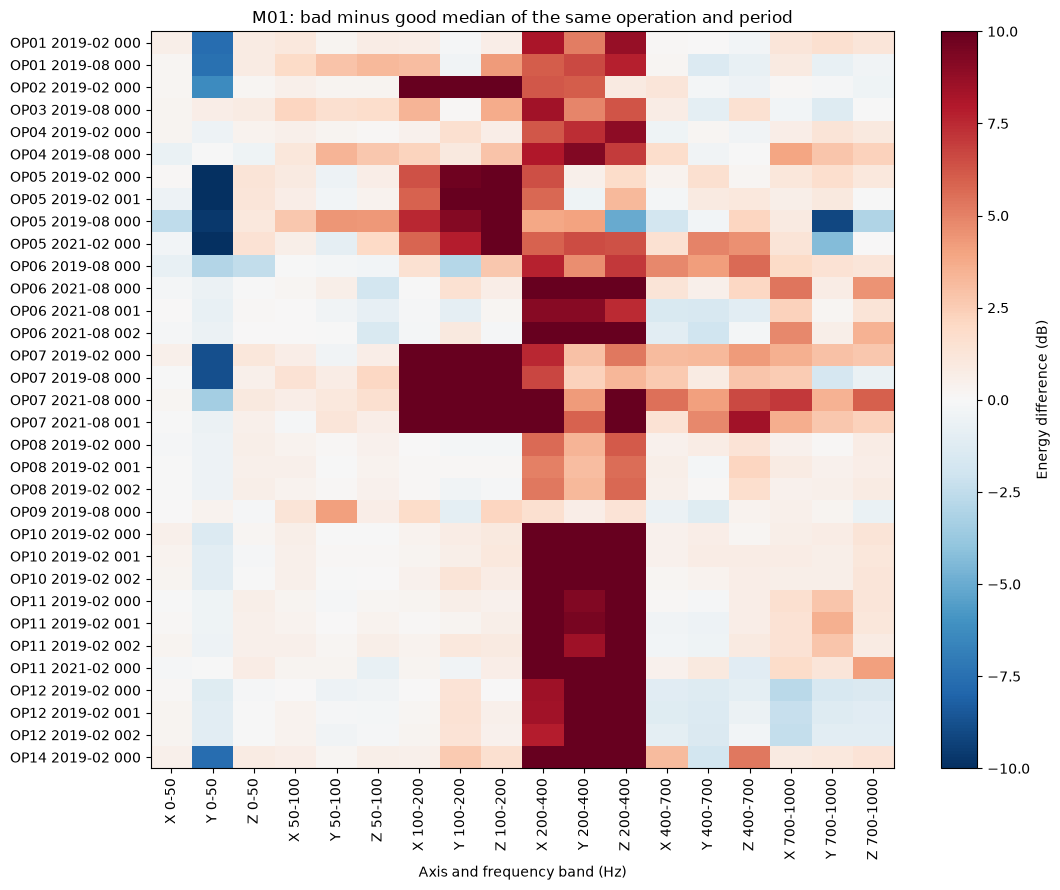

In [10]:
cols = [f'{ax} {lo}-{hi}' for lo, hi in BANDS for ax in AXES]
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(diff[cols], cmap='RdBu_r', vmin=-10, vmax=10, aspect='auto')
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(diff)), diff['op'] + ' ' + diff['period'] + ' ' + diff['num'])
ax.set(xlabel='Axis and frequency band (Hz)', title='M01: bad minus good median of the same operation and period')
fig.colorbar(im, label='Energy difference (dB)')
fig.tight_layout()
fig.savefig('../results/figures/m01_bad_vs_good_heatmap.png', dpi=150)
plt.show()

### Summary per bad recording
For each bad recording: the band and axis with the biggest change, and whether the 200–400 Hz band (which holds the spindle speed) is up by more than 3 dB on at least one axis. 3 dB means about twice the energy.

In [11]:
spindle = [f'{ax} 200-400' for ax in AXES]
summary = diff[['op', 'period', 'num', 'n_good']].copy()
summary['biggest change'] = diff[cols].abs().idxmax(axis=1)
summary['dB'] = [diff.loc[i, c] for i, c in summary['biggest change'].items()]
summary['spindle band max dB'] = diff[spindle].max(axis=1)
summary['rms max dB'] = diff[[f'rms {ax}' for ax in AXES]].max(axis=1)
print(summary.round(1).to_string(index=False))
up = summary['spindle band max dB'] > 3
print(f"\nspindle band up > 3 dB on some axis: {up.sum()} of {len(summary)}")
print(f"biggest change inside 200-400 Hz: {summary['biggest change'].str.contains('200-400').sum()} of {len(summary)}")
print(f"RMS up > 1 dB on some axis: {(summary['rms max dB'] > 1).sum()} of {len(summary)}")

  op  period num  n_good biggest change    dB  spindle band max dB  rms max dB
OP01 2019-02 000       5      Z 200-400   8.7                  8.7         2.7
OP01 2019-08 000      14      Z 200-400   7.8                  7.8         3.4
OP02 2019-02 000       5      Y 100-200  17.3                  6.2         8.3
OP03 2019-08 000      14      X 200-400   8.4                  8.4         3.6
OP04 2019-02 000       5      Z 200-400   9.0                  9.0         3.8
OP04 2019-08 000      15      Y 200-400   9.2                  9.2         4.6
OP05 2019-02 000       3         Y 0-50 -12.0                  6.4         1.5
OP05 2019-02 001       3         Y 0-50 -12.6                  5.8         1.7
OP05 2019-08 000      16      Z 100-200  11.0                  4.1         0.1
OP05 2021-02 000       9         Y 0-50 -20.2                  6.5         2.1
OP06 2019-08 000       4      X 200-400   7.7                  7.7         3.0
OP06 2021-08 000       1      Y 200-400  16.6       

### Energy at each operation's own spindle speed
In the table above, the 200 Hz operations (OP02, OP05, OP07) show their biggest change in the 100–200 Hz band. Their spindle speed sits exactly on that band's edge, so the fixed bands split the peak in two. Here I use a band of ±10% around each operation's own speed instead: 225–275 Hz for 250 Hz operations, 180–220 Hz for 200 Hz ones.

In [12]:
summary['own speed max dB'] = diff[[f'spindle {ax}' for ax in AXES]].max(axis=1)
print(summary[['op', 'period', 'num', 'own speed max dB', 'rms max dB']].round(1).to_string(index=False))
for t in [3, 6, 10]:
    print(f"own spindle band up > {t} dB on some axis: {(summary['own speed max dB'] > t).sum()} of {len(summary)}")

  op  period num  own speed max dB  rms max dB
OP01 2019-02 000              12.7         2.7
OP01 2019-08 000              11.0         3.4
OP02 2019-02 000              22.3         8.3
OP03 2019-08 000              10.3         3.6
OP04 2019-02 000              10.7         3.8
OP04 2019-08 000              11.8         4.6
OP05 2019-02 000              17.2         1.5
OP05 2019-02 001              16.7         1.7
OP05 2019-08 000              18.6         0.1
OP05 2021-02 000              19.9         2.1
OP06 2019-08 000               9.2         3.0
OP06 2021-08 000              17.4         9.0
OP06 2021-08 001              10.5         4.6
OP06 2021-08 002              17.4         8.9
OP07 2019-02 000              19.2         4.2
OP07 2019-08 000              17.1         2.4
OP07 2021-08 000              28.0         7.9
OP07 2021-08 001              30.4         9.9
OP08 2019-02 000               7.2         2.6
OP08 2019-02 001               6.5         2.5
OP08 2019-02 

### What Day 2 shows
- **One pattern across all operations.** 32 of 33 bad recordings have more than 6 dB more energy within ±10% of their own spindle speed than the good runs of the same group, and 28 of 33 more than 10 dB. The OP01 finding from Day 1 holds for the whole machine.
- **The 200 Hz operations only looked different.** OP02, OP05 and OP07 seemed to change in the 100–200 Hz band, but that was the spindle peak split by the band edge at 200 Hz. With a band around their own speed they show the biggest increases of all (17 to 30 dB).
- **RMS alone is a weak signal.** The overall RMS rises much less than the spindle band. OP05 2019-08 has +18.6 dB at its spindle speed but only +0.1 dB in RMS. An RMS threshold would miss it.
- **One exception:** OP09 2019-08 differs by only 2.2 dB at the spindle speed and 0.1 dB in RMS. It looks like a normal run, and I can't tell from the data why it is labelled bad.
- **Y below 50 Hz is often lower** in bad files (blue column in the heatmap). This fits the cut-off start and end of bad files from Day 1 and is not something a model should learn.

**What this means for the model:** the most useful feature is the energy in a band around each operation's spindle speed, which needs one model per operation. Some groups have only 1 to 3 good recordings, so these dB values are rough, but the direction is the same in 32 of 33 cases.